
1. Перші 5 рядків датасету:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
2,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
3,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
4,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
5,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S



2. Розмір датасету: рядків — 891, стовпців — 12

Типи даних:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

3. Кількість пропущених значень до обробки:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Кількість пропусків після очищення:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

4. Знайдено дублікатів: 0

5. Описова статистика числових показників:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.36,0.52,0.38,32.20
std,257.35,0.49,0.84,13.02,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,22.00,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33



6. Відсоток виживання залежно від статі (Sex):


,Survival Rate (%)
Sex,
female,74.20
male,18.89



Відсоток виживання залежно від класу каюти (Pclass):


,Survival Rate (%)
Pclass,
1,62.96
2,47.28
3,24.24


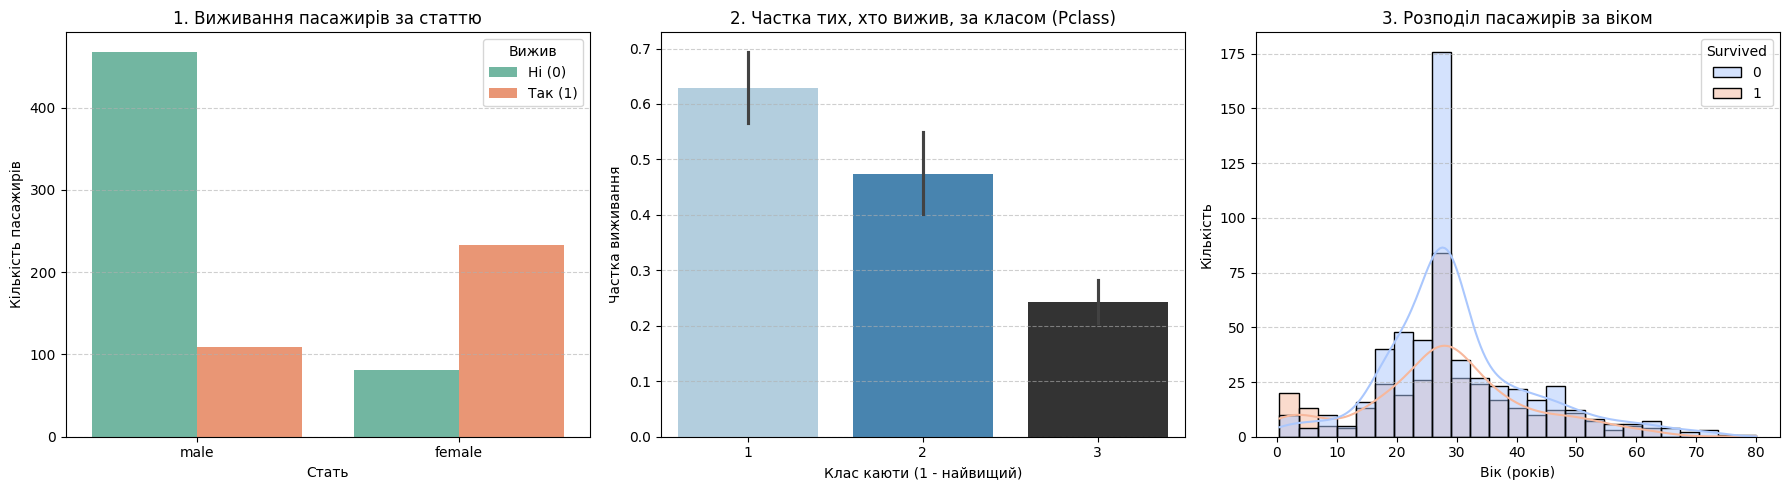

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Налаштовуємо відображення чисел (2 знаки після коми)
pd.options.display.float_format = '{:,.2f}'.format

# --- 1. Завантаження датасету Titanic ---
file_path = 'titanic.csv'


url_fallback = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df_titanic = pd.read_csv(url_fallback)


# Робимо нумерацію рядків з 1
df_titanic.index = df_titanic.index + 1

print("\n1. Перші 5 рядків датасету:")
display(df_titanic.head())

# --- 2. Розмір та структура даних ---
print(f"\n2. Розмір датасету: рядків — {df_titanic.shape[0]}, стовпців — {df_titanic.shape[1]}")
print("\nТипи даних:")
print(df_titanic.dtypes)

# --- 3. Перевірка та обробка пропущених значень ---
print("\n3. Кількість пропущених значень до обробки:")
print(df_titanic.isnull().sum())

# Заповнюємо пропущений вік (Age) медіанним значенням, а тариф (Fare) — середнім
if 'Age' in df_titanic.columns:
    df_titanic['Age'] = df_titanic['Age'].fillna(df_titanic['Age'].median())
if 'Fare' in df_titanic.columns:
    df_titanic['Fare'] = df_titanic['Fare'].fillna(df_titanic['Fare'].mean())
if 'Embarked' in df_titanic.columns:
    df_titanic['Embarked'] = df_titanic['Embarked'].fillna(df_titanic['Embarked'].mode()[0])

# Стовпець Cabin зазвичай має понад 70% пропусків, тому його доцільно видалити
if 'Cabin' in df_titanic.columns:
    df_titanic = df_titanic.drop(columns=['Cabin'])

print("\nКількість пропусків після очищення:")
print(df_titanic.isnull().sum())

# --- 4. Перевірка дублікатів та описова статистика ---
print(f"\n4. Знайдено дублікатів: {df_titanic.duplicated().sum()}")
df_titanic = df_titanic.drop_duplicates()

print("\n5. Описова статистика числових показників:")
display(df_titanic.describe())

# --- 6. Аналітичні групування ---
print("\n6. Відсоток виживання залежно від статі (Sex):")
display((df_titanic.groupby('Sex')['Survived'].mean() * 100).to_frame(name='Survival Rate (%)'))

print("\nВідсоток виживання залежно від класу каюти (Pclass):")
display((df_titanic.groupby('Pclass')['Survived'].mean() * 100).to_frame(name='Survival Rate (%)'))

# --- 7. Візуалізація (3 графіки для Titanic) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Графік 1: Виживання за статтю
sns.countplot(data=df_titanic, x='Sex', hue='Survived', palette='Set2', ax=axes[0])
axes[0].set_title('1. Виживання пасажирів за статтю')
axes[0].set_xlabel('Стать')
axes[0].set_ylabel('Кількість пасажирів')
axes[0].legend(title='Вижив', labels=['Ні (0)', 'Так (1)'])
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Графік 2: Виживання за класом каюти
sns.barplot(data=df_titanic, x='Pclass', y='Survived', hue='Pclass', palette='Blues_d', legend=False, ax=axes[1])
axes[1].set_title('2. Частка тих, хто вижив, за класом (Pclass)')
axes[1].set_xlabel('Клас каюти (1 - найвищий)')
axes[1].set_ylabel('Частка виживання')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

# Графік 3: Розподіл віку пасажирів
sns.histplot(data=df_titanic, x='Age', hue='Survived', bins=25, kde=True, palette='coolwarm', ax=axes[2])
axes[2].set_title('3. Розподіл пасажирів за віком')
axes[2].set_xlabel('Вік (років)')
axes[2].set_ylabel('Кількість')
axes[2].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

1. Початкова таблиця з Вікіпедії (перші 5 рядків):


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
1,Крим,23.00,20.60,16.00,13.00,7.30,12.60,—,—
2,Вінницька,22.40,19.20,14.20,12.40,8.40,11.20,10.9,7.6
3,Волинська,24.70,25.00,17.90,15.30,11.20,14.80,14.1,10.1
4,Дніпропетровська,20.40,20.40,15.10,12.30,7.10,11.20,11.1,7.1
5,Донецька,27.10,21.40,14.00,10.90,6.10,9.80,8.2,—



2. Початковий розмір таблиці: (28, 9)

3. Кількість пропущених значень по роках до заповнення:
Регіон    0
1950      2
1960      1
1970      1
1990      0
2000      0
2012      0
2014      2
2019      4
dtype: int64

4. Повний очищений датасет:


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
1,Крим,23.00,20.60,16.00,13.00,7.30,12.60,11.14,8.02
2,Вінницька,22.40,19.20,14.20,12.40,8.40,11.20,10.90,7.60
3,Волинська,24.70,25.00,17.90,15.30,11.20,14.80,14.10,10.10
4,Дніпропетровська,20.40,20.40,15.10,12.30,7.10,11.20,11.10,7.10
5,Донецька,27.10,21.40,14.00,10.90,6.10,9.80,8.20,8.02
6,Житомирська,26.10,22.30,15.90,12.90,8.90,12.20,12.00,7.90
7,Закарпатська,31.40,27.30,20.70,16.80,11.50,15.10,14.60,10.40
8,Запорізька,21.90,19.70,15.00,12.40,7.10,10.60,10.60,6.80
9,Івано-Франківська,24.30,24.80,18.20,15.50,10.30,12.40,12.20,8.80
10,Київська,20.40,18.90,15.60,12.30,7.30,12.20,12.10,8.00



5. Описова статистика за роками:


,1950,1960,1970,1990,2000,2012,2014,2019
count,27.00,27.00,27.00,27.00,27.00,27.00,27.00,27.00
mean,23.10,20.76,15.60,13.06,8.22,11.66,11.14,8.02
std,2.77,2.94,1.87,1.55,1.58,1.67,1.97,1.36
min,18.60,16.30,12.70,10.80,6.10,9.40,5.10,6.00
25%,21.20,18.65,14.40,12.15,7.05,10.30,10.35,6.95
50%,23.00,20.40,15.50,12.60,7.90,11.50,11.14,8.00
75%,24.50,22.05,16.30,14.10,9.00,12.30,12.10,8.75
max,31.40,27.30,20.70,16.80,11.80,15.90,14.80,11.00



6. Середній коефіцієнт народжуваності по Україні за роками:
1950   23.10
1960   20.76
1970   15.60
1990   13.06
2000    8.22
2012   11.66
2014   11.14
2019    8.02
dtype: float64

Лідери народжуваності: у 1950 році -> Закарпатська, у 2019 році -> Київ


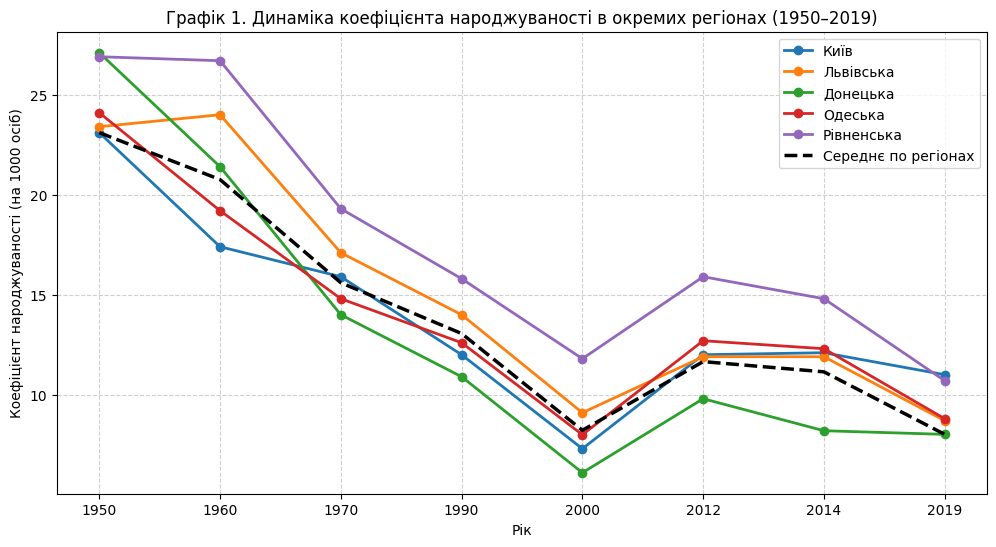

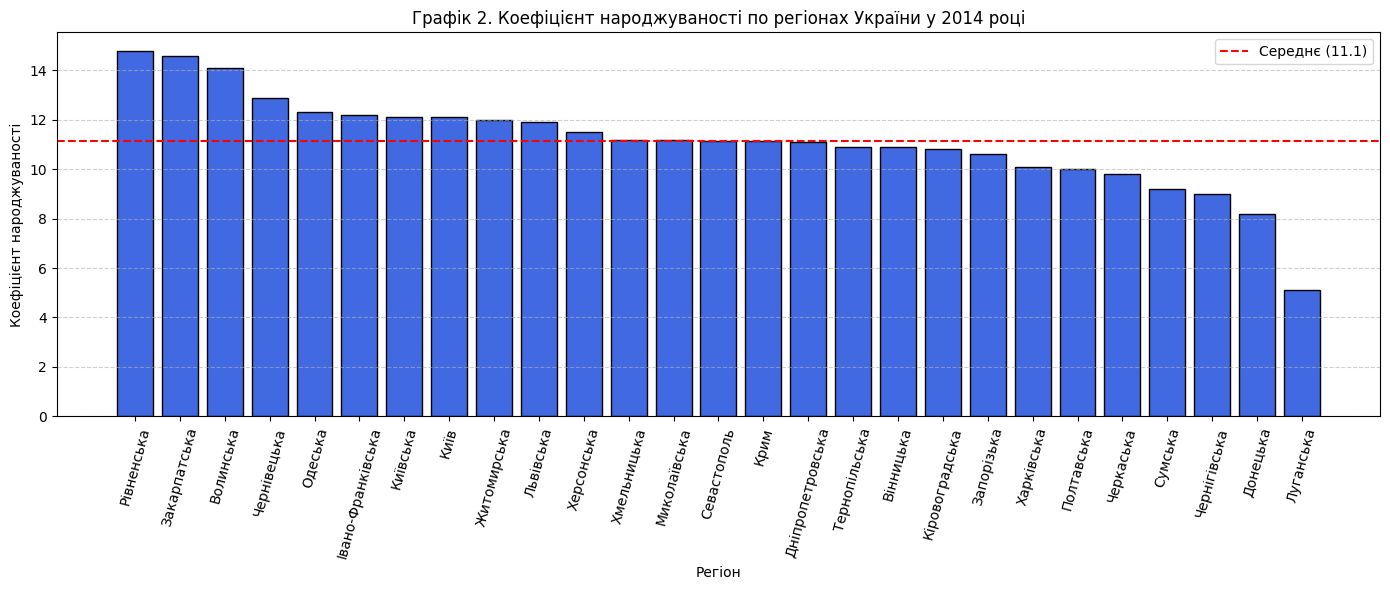

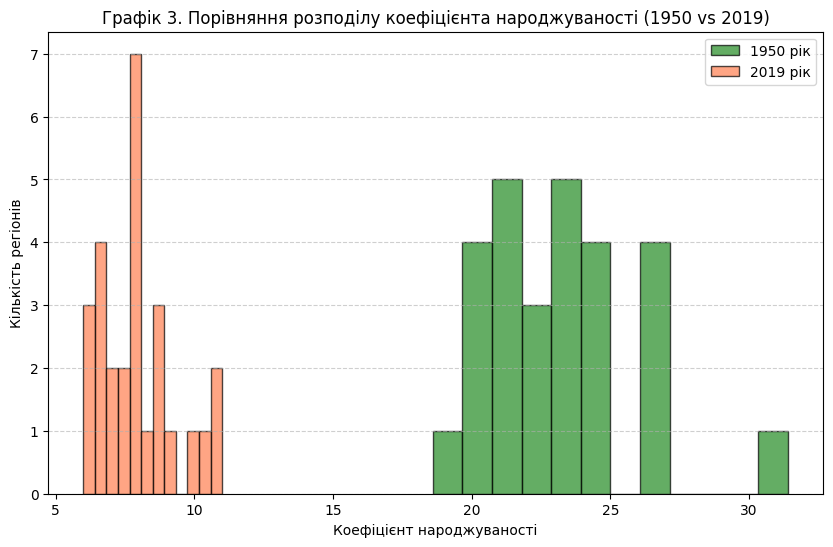

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO

# Повертаємо формат виведення до 2 знаків після коми
pd.options.display.float_format = '{:,.2f}'.format

# --- 1. Зчитування таблиці з Вікіпедії (з обходом помилки 403) ---
url_ukr = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8'

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'
}

response = requests.get(url_ukr, headers=headers)

# Шукаємо таблицю з текстом "Коефіцієнт народжуваності в регіонах України"
tables = pd.read_html(
    StringIO(response.text),
    match='Коефіцієнт народжуваності в регіонах України',
    decimal=',',
    thousands='.'
)

df_ua = tables[0]

# ОДРАЗУ робимо нумерацію з 1 для початкової таблиці
df_ua.index = df_ua.index + 1

print("1. Початкова таблиця з Вікіпедії (перші 5 рядків):")
display(df_ua.head())

# --- 2. Розмір та очищення даних ---
print(f"\n2. Початковий розмір таблиці: {df_ua.shape}")

# Замінюємо всі види тире на NaN
df_ua = df_ua.replace(['—', '–', '-', ''], np.nan)

# Видаляємо останній підсумковий рядок "Україна"
df_ua = df_ua[df_ua['Регіон'] != 'Україна'].copy()

# Переводимо всі стовпці з роками у числовий формат float
year_cols = df_ua.columns[1:]
for col in year_cols:
    if df_ua[col].dtype == 'object':
        df_ua[col] = df_ua[col].astype(str).str.replace(',', '.', regex=False)
    df_ua[col] = pd.to_numeric(df_ua[col], errors='coerce')

print("\n3. Кількість пропущених значень по роках до заповнення:")
print(df_ua.isnull().sum())

# Заповнюємо пропущені значення середнім значенням відповідного стовпця (року)
for col in year_cols:
    df_ua[col] = df_ua[col].fillna(df_ua[col].mean())

# Оновлюємо нумерацію з 1 після видалення рядка "Україна"
df_ua = df_ua.reset_index(drop=True)
df_ua.index = df_ua.index + 1

print("\n4. Повний очищений датасет:")
display(df_ua)

# --- 3. Статистичний аналіз ---
print("\n5. Описова статистика за роками:")
display(df_ua.describe())

print("\n6. Середній коефіцієнт народжуваності по Україні за роками:")
print(df_ua[year_cols].mean())

# Знаходимо регіон з найвищою народжуваністю у 2019 році та у 1950 році
max_1950 = df_ua.loc[df_ua['1950'].idxmax(), 'Регіон']
max_2019 = df_ua.loc[df_ua['2019'].idxmax(), 'Регіон']
print(f"\nЛідери народжуваності: у 1950 році -> {max_1950}, у 2019 році -> {max_2019}")

# --- 4. Побудова 3 графіків для народжуваності в Україні ---

# Графік 1: Динаміка народжуваності по роках для 5 регіонів + середнє по країні
plt.figure(figsize=(12, 6))
regions_to_plot = ['Київ', 'Львівська', 'Донецька', 'Одеська', 'Рівненська']

for reg in regions_to_plot:
    row = df_ua[df_ua['Регіон'] == reg]
    if not row.empty:
        plt.plot(year_cols, row[year_cols].values[0], marker='o', linewidth=2, label=reg)

plt.plot(year_cols, df_ua[year_cols].mean(), color='black', linestyle='--', linewidth=2.5, label='Середнє по регіонах')

plt.title('Графік 1. Динаміка коефіцієнта народжуваності в окремих регіонах (1950–2019)')
plt.xlabel('Рік')
plt.ylabel('Коефіцієнт народжуваності (на 1000 осіб)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Графік 2: Стовпчаста діаграма коефіцієнта народжуваності за 2014 рік по всіх регіонах
plt.figure(figsize=(14, 6))
df_sorted_2014 = df_ua.sort_values(by='2014', ascending=False)
plt.bar(df_sorted_2014['Регіон'], df_sorted_2014['2014'], color='royalblue', edgecolor='black')
plt.axhline(df_ua['2014'].mean(), color='red', linestyle='--', label=f"Середнє ({df_ua['2014'].mean():.1f})")
plt.title('Графік 2. Коефіцієнт народжуваності по регіонах України у 2014 році')
plt.xlabel('Регіон')
plt.ylabel('Коефіцієнт народжуваності')
plt.xticks(rotation=75)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Графік 3: Порівняння розподілу народжуваності у 1950 та 2019 роках
plt.figure(figsize=(10, 6))
plt.hist(df_ua['1950'], bins=12, alpha=0.7, label='1950 рік', color='forestgreen', edgecolor='black')
plt.hist(df_ua['2019'], bins=12, alpha=0.7, label='2019 рік', color='coral', edgecolor='black')
plt.title('Графік 3. Порівняння розподілу коефіцієнта народжуваності (1950 vs 2019)')
plt.xlabel('Коефіцієнт народжуваності')
plt.ylabel('Кількість регіонів')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()